# HypotheSAEs on Drugs.com reviews: what distinguishes positive from negative medication reviews?

Runs the HypotheSAEs pipeline (embed → SAE → select neurons → interpret → evaluate) on the **UCI Drug Review dataset** (Gräßer et al., 2018; CC BY 4.0): patient reviews of medications from Drugs.com, each with a 1–10 rating. Label = 1 for positive reviews (rating 9–10), 0 for negative reviews (rating 1–4); middle ratings are dropped.

Same setup as `quickstart_hippocorpus.ipynb`:
- **Embeddings + SAE** in this Colab session (GPU runtime: *Runtime → Change runtime type → T4 GPU*).
- **LLM** (interpretation + annotation): Qwen3-8B via vLLM on Modal (`modal/vllm_server.py`), with `prompt_suffix=" /no_think"` for annotation.

Needs the Colab secret `MODAL_VLLM_KEY` (key icon in the left sidebar), with notebook access enabled.

In [1]:
!pip install -q git+https://github.com/psnandini/HypotheSAEs.git
!nvidia-smi --query-gpu=name,memory.total --format=csv

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
import os
from google.colab import userdata, files

os.environ["OPENAI_BASE_URL"] = "https://psnandini--hypothesaes-vllm-serve.us-east.modal.run/v1"
os.environ["OPENAI_KEY_SAE"] = userdata.get("MODAL_VLLM_KEY")
os.environ["EMB_CACHE_DIR"] = "/content/emb_cache"

import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hypothesaes.quickstart import train_sae, interpret_sae, generate_hypotheses, evaluate_hypotheses
from hypothesaes.embedding import get_local_embeddings
from hypothesaes.llm_api import get_completion

MODEL = "Qwen/Qwen3-8B"
INTERPRETER_MODEL = ANNOTATOR_MODEL = MODEL
OUT = "/content/results"   # every result table is saved here and downloaded right away
os.makedirs(OUT, exist_ok=True)

**Wake up the LLM server.** It scales to zero when idle, so the first call can take 2–3 minutes.

In [3]:
import time
t = time.time()
print(get_completion(prompt="Reply with the single word: ready /no_think", model=MODEL))
print(f"{time.time() - t:.0f} s")



ready
69 s


## 0. Load the drug reviews

The same review often appears several times (listed under a brand and a generic name), so we drop duplicate texts before sampling; otherwise a review could land in both training and held-out data. We then take a balanced random sample of 3,000 positive and 3,000 negative reviews and split it 70/10/20 into train / validation / held-out.

In [4]:
!wget -q -nc https://archive.ics.uci.edu/ml/machine-learning-databases/00462/drugsCom_raw.zip
!unzip -q -o drugsCom_raw.zip -d drugs

df = pd.concat([pd.read_csv(f"drugs/{f}", sep="\t") for f in ["drugsComTrain_raw.tsv", "drugsComTest_raw.tsv"]])
df["review"] = df.review.map(html.unescape).str.strip().str.strip('"').str.strip()
df = df.drop_duplicates(subset="review")
print(f"{len(df)} unique reviews")

df = df[(df.rating >= 9) | (df.rating <= 4)].copy()
df["label"] = (df.rating >= 9).astype(int)
df = df.groupby("label").sample(n=3000, random_state=0).sample(frac=1, random_state=0).reset_index(drop=True)
df["n_words"] = df.review.str.split().str.len()

n = len(df)
df["split"] = np.select([df.index < 0.7 * n, df.index < 0.8 * n], ["train", "val"], "holdout")
print(df.groupby(["split", "label"]).size().unstack())

train_df, val_df, holdout_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "holdout"])
texts, labels = train_df.review.tolist(), train_df.label.values
val_texts = val_df.review.tolist()

128461 unique reviews
label       0     1
split              
holdout   594   606
train    2113  2087
val       293   307


Quick checks: review length by class, and the most common conditions in the sample.

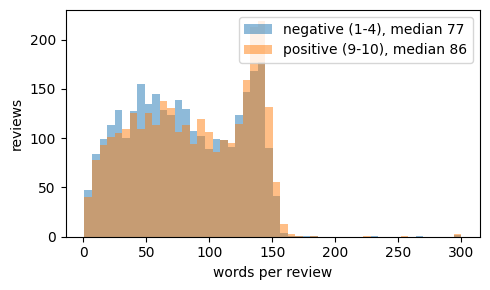

condition
Birth Control              921
Depression                 312
Pain                       222
Anxiety                    217
Acne                       206
Vaginal Yeast Infection    185
Insomnia                   177
Bipolar Disorde            153
Weight Loss                141
Obesity                    115
Name: count, dtype: int64


In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
for lab, g in df.groupby("label"):
    name = "positive (9-10)" if lab else "negative (1-4)"
    ax.hist(g.n_words.clip(upper=300), bins=50, alpha=0.5, label=f"{name}, median {g.n_words.median():.0f}")
ax.set_xlabel("words per review"); ax.set_ylabel("reviews"); ax.legend(); plt.tight_layout(); plt.show()
print(df.condition.value_counts().head(10))

## 1. Text embeddings

`nomic-ai/modernbert-embed-base`, cached in `EMB_CACHE_DIR`.

In [6]:
EMBEDDER = "nomic-ai/modernbert-embed-base"
text2embedding = get_local_embeddings(texts + val_texts, model=EMBEDDER, batch_size=64, cache_name="drugs_modernbert")
train_embeddings = np.stack([text2embedding[t] for t in texts])
val_embeddings = np.stack([text2embedding[t] for t in val_texts])
print(train_embeddings.shape, val_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/210 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/445k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  596MB            

... (6 outputs left out)

Loaded model nomic-ai/modernbert-embed-base to cuda


Processing chunks:   0%|          | 0/1 [00:00<?, ?it/s]

Chunk 0:   0%|          | 0/75 [00:00<?, ?it/s]

Saved 4800 embeddings to /content/emb_cache/drugs_modernbert/chunk_000.npy
(4200, 768) (600, 768)


## 2. Train the SAE

Same settings as the Hippocorpus run (M=256, K=8, Matryoshka prefixes [32, 256]); ~4.2K training reviews.

In [7]:
sae = train_sae(
    embeddings=train_embeddings, M=256, K=8, matryoshka_prefix_lengths=[32, 256],
    checkpoint_dir="/content/checkpoints/drugs", val_embeddings=val_embeddings,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Early stopping triggered after 92 epochs
Saved model to /content/checkpoints/drugs/SAE_matryoshka_M=256_K=8_prefixes=32-256.pt


## 3. Sanity check: interpret a few random neurons

The instructions ask for specific content rather than overall satisfaction, since "the reviewer likes the drug" would separate the classes but explain nothing.

In [8]:
TASK_SPECIFIC_INSTRUCTIONS = """All of the texts are patient reviews of a medication, posted on Drugs.com.
Features should describe a specific property of the review's content, such as a particular symptom, side effect, or experience,
rather than general satisfaction with the drug. For example:
- "mentions a specific dosage in milligrams"
- "mentions taking the medication for several years"
"""

INTERPRET_LLM_KWARGS = {}                                # thinking on for interpretation
ANNOTATION_LLM_KWARGS = {"prompt_suffix": " /no_think"}  # thinking off for yes/no annotation

random_results = interpret_sae(
    texts=texts, embeddings=train_embeddings, sae=sae,
    interpreter_model=INTERPRETER_MODEL, n_random_neurons=5, print_examples_n=3,
    task_specific_instructions=TASK_SPECIFIC_INSTRUCTIONS, interpret_llm_kwargs=INTERPRET_LLM_KWARGS,
)

Computing activations (batchsize=16384):   0%|          | 0/1 [00:00<?, ?it/s]

Activations shape: (4200, 256)


Generating interpretations:   0%|          | 0/5 [00:00<?, ?it/s]


Neuron 169 (2.0% active): mentions Fibromyalgia

Top activating examples:
1. Ultram is the only medicine that stops the Fibromyalgia pain.
2. Really wanted this to work had allergic reaction to Cymbalta but it was helping fibro so tried Savella. Have been doing titration pack. Never got higher than 50 mg in 3 weeks but my neck has been stiff, headache, stomach pain, bloating, anxiety increased achy feeling like the flu. So I plan to stop it and see if things improve . Diagnosed with fibromyalgia 20 years ago and haven't felt this bad in a long time. So disappointed.
3. I was diagnosed with fibromyalgia when I was 22 and I am about to turn 57 on the 27th of August. It really never bothered me until the last 8 years, and it hit me like a ton of knives. I have tried everything and nothing seems to help. I went to a rheumatologist and she diagnosed me with polymyalgia along with the fibromyalgia. Had neck surgery in July of last year and back surgery in December, and I can honestly say th

## 4. Generate hypotheses

Select the 20 neurons most correlated with the label, interpret each, and score fidelity. The table is saved and downloaded as soon as it is ready.

In [9]:
results = generate_hypotheses(
    texts=texts, labels=labels, embeddings=train_embeddings, sae=sae,
    interpreter_model=INTERPRETER_MODEL, annotator_model=ANNOTATOR_MODEL,
    selection_method="correlation", n_selected_neurons=20, n_candidate_interpretations=1,
    task_specific_instructions=TASK_SPECIFIC_INSTRUCTIONS,
    interpret_llm_kwargs=INTERPRET_LLM_KWARGS, annotation_llm_kwargs=ANNOTATION_LLM_KWARGS,
    n_workers_interpretation=8, n_workers_annotation=32,
)
pd.set_option("display.max_colwidth", None)
display(results.sort_values("target_correlation", ascending=False))
results.to_csv(f"{OUT}/drugs_hypotheses.csv", index=False)
files.download(f"{OUT}/drugs_hypotheses.csv")

Embeddings shape: (4200, 768)


Computing activations (batchsize=16384):   0%|          | 0/1 [00:00<?, ?it/s]

Activations shape: (4200, 256)

Step 1: Selecting top 20 predictive neurons

Step 2: Interpreting selected neurons


/usr/local/lib/python3.13/dist-packages/hypothesaes/select_neurons.py:130: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearsonr(activations[:, i], target)[0]


Generating interpretations:   0%|          | 0/20 [00:00<?, ?it/s]


Step 3: Scoring Interpretations
Found 0 cached items; annotating 2000 uncached items


Scoring neuron interpretation fidelity (20 neurons; 1 candidate interps per neuron; 100 examples to score each…

,neuron_idx,target_correlation,interpretation,f1_fidelity_score
0,5,0.657769,mentions a specific dosage in milligrams,0.289474
2,29,0.245225,mentions the medication caused the user to feel happy or energetic,0.717391
8,22,0.112469,mentions anxiety or panic attacks,0.793651
9,17,0.108489,mentions the medication being effective for a specific pain-related condition,0.737705
10,36,0.100923,mentions absence of side effects,0.694215
12,10,0.098646,mentions the medication being used to treat opiate addiction,0.857143
13,20,0.098389,mentions the medication by name (Chantix/Champix),0.808081
17,7,0.092296,mentions Suboxone as a treatment for opiate addiction,0.417910
19,19,0.088017,"mentions specific weight metrics (e.g., pounds, lbs, or numerical values) related to weight loss progress",0.969697
18,123,-0.092127,"mentions experiencing severe side effects such as vision blurriness, lethargy, and dry skin",0.771930


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Evaluate on held-out reviews

Annotate each hypothesis on the 1,200 held-out reviews and test whether it predicts positive vs negative.

In [10]:
metrics, evaluation_df = evaluate_hypotheses(
    hypotheses_df=results, texts=holdout_df.review.tolist(), labels=holdout_df.label.values,
    annotator_model=ANNOTATOR_MODEL, annotation_llm_kwargs=ANNOTATION_LLM_KWARGS, n_workers_annotation=32,
)
evaluation_df.to_csv(f"{OUT}/drugs_holdout_eval.csv", index=False)
files.download(f"{OUT}/drugs_holdout_eval.csv")
display(evaluation_df)
print(f"AUROC: {metrics['auroc']:.3f}")
print(f"Significant hypotheses: {metrics['Significant'][0]}/{metrics['Significant'][1]} (p < {metrics['Significant'][2]})")

Step 1: Annotating texts with 20 hypotheses
Found 0 cached items; annotating 24000 uncached items


Annotating:   0%|          | 0/24000 [00:00<?, ?it/s]

Step 2: Computing predictiveness of hypothesis annotations
Optimization terminated successfully.
         Current function value: 0.373658
         Iterations 7


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,hypothesis,separation_score,separation_pval,regression_coef,regression_pval,feature_prevalence
2,mentions the medication caused the user to feel happy or energetic,0.482844,3.512617e-55,2.030208,1.123744e-18,0.272500
9,mentions the medication being effective for a specific pain-related condition,0.403373,1.694370e-44,2.109267,1.646065e-22,0.635000
10,mentions absence of side effects,0.111758,1.046343e-04,0.805023,2.195627e-05,0.495833
12,mentions the medication being used to treat opiate addiction,0.086378,1.339939e-02,0.400982,8.425049e-02,0.218333
0,mentions a specific dosage in milligrams,0.073900,2.516617e-02,0.015418,9.404537e-01,0.257500
19,"mentions specific weight metrics (e.g., pounds, lbs, or numerical values) related to weight loss progress",0.042147,3.089368e-01,0.377277,1.321779e-01,0.141667
13,mentions the medication by name (Chantix/Champix),-0.063590,8.562816e-02,-0.157477,5.094447e-01,0.187500
17,mentions Suboxone as a treatment for opiate addiction,-0.082707,2.666627e-01,0.157537,7.470789e-01,0.039167
16,mentions not getting pregnant,-0.147674,8.051023e-06,0.166759,5.229687e-01,0.253333
7,mentions prolonged menstrual bleeding,-0.235122,1.386264e-10,-0.482847,9.403873e-02,0.188333


AUROC: 0.913
Significant hypotheses: 8/20 (p < 0.005)
